# Klasifikasi sampah: Organik, Plastik, Kertas

Notebook ini menjalankan pipeline yang sama dengan model yang dideploy: persiapan dataset, pelatihan
MobileNetV3-Small (transfer learning, PyTorch), evaluasi sekali pada data uji terpisah, lalu ekspor ONNX
yang dipakai layanan FastAPI.

**Dataset:** RealWaste, Single, Iranmanesh dan Raad (2023), DOI [10.24432/C5SS4G](https://doi.org/10.24432/C5SS4G),
rilis asli [sam-single/realwaste](https://github.com/sam-single/realwaste). Kelas asli dipetakan ke tiga kategori:
*Food Organics* + *Vegetation* → Organik, *Plastic* → Plastik, *Paper* → Kertas.

Jalankan dari root repository atau folder `ml`, memakai environment dari `requirements-train.txt` (Python 3.12).

In [1]:
import csv, json, subprocess, sys, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage

ML = Path.cwd() if Path.cwd().name == "ml" else Path.cwd() / "ml"
assert (ML / "scripts/train.py").exists(), "Jalankan notebook dari root repository atau folder ml"
CLASSES = ["ORGANIC", "PLASTIC", "PAPER"]
LABELS = {"ORGANIC": "Organik", "PLASTIC": "Plastik", "PAPER": "Kertas"}


def run(script, *args):
    """Run a checked-in script and stream its log into this notebook."""
    process = subprocess.Popen(
        [sys.executable, "-u", str(ML / "scripts" / script), *args],
        cwd=ML, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for line in process.stdout:
        print(line, end="")
    assert process.wait() == 0, f"{script} failed"


import torch
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

PyTorch 2.11.0+cu128 | CUDA: True NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Dataset

`download_subset.py` mengunduh rilis yang dipin dan memverifikasi hash Git serta SHA-256.
`prepare.py` membuang file rusak, mengelompokkan foto yang mirip (dHash) agar foto hampir kembar
tidak bocor antar split, lalu membagi train/validation/test secara berkelompok dengan seed tetap.
Hasilnya tercatat di `manifest.csv`.

In [2]:
if not (ML / "data/realwaste-main").exists():
    run("download_subset.py")
    run("prepare.py", "--archive", "realwaste-subset.zip")

rows = list(csv.DictReader((ML / "manifest.csv").open(encoding="utf-8")))
counts = Counter((r["split"], r["category"]) for r in rows)
print(f"Total gambar setelah validasi: {len(rows)}\n")
print(f"{'Split':<12}" + "".join(f"{LABELS[c]:>10}" for c in CLASSES) + f"{'Total':>10}")
for split in ["train", "validation", "test"]:
    values = [counts[(split, c)] for c in CLASSES]
    print(f"{split:<12}" + "".join(f"{v:>10}" for v in values) + f"{sum(values):>10}")

groups = {}
for r in rows:
    groups.setdefault(r["group"], set()).add(r["split"])
assert all(len(splits) == 1 for splits in groups.values()), "Grup foto mirip tidak boleh lintas split"
print("\nTidak ada grup foto mirip yang muncul di lebih dari satu split.")

Total gambar setelah validasi: 2268

Split          Organik   Plastik    Kertas     Total
train              593       645       350      1588
validation         127       138        75       340
test               127       138        75       340

Tidak ada grup foto mirip yang muncul di lebih dari satu split.


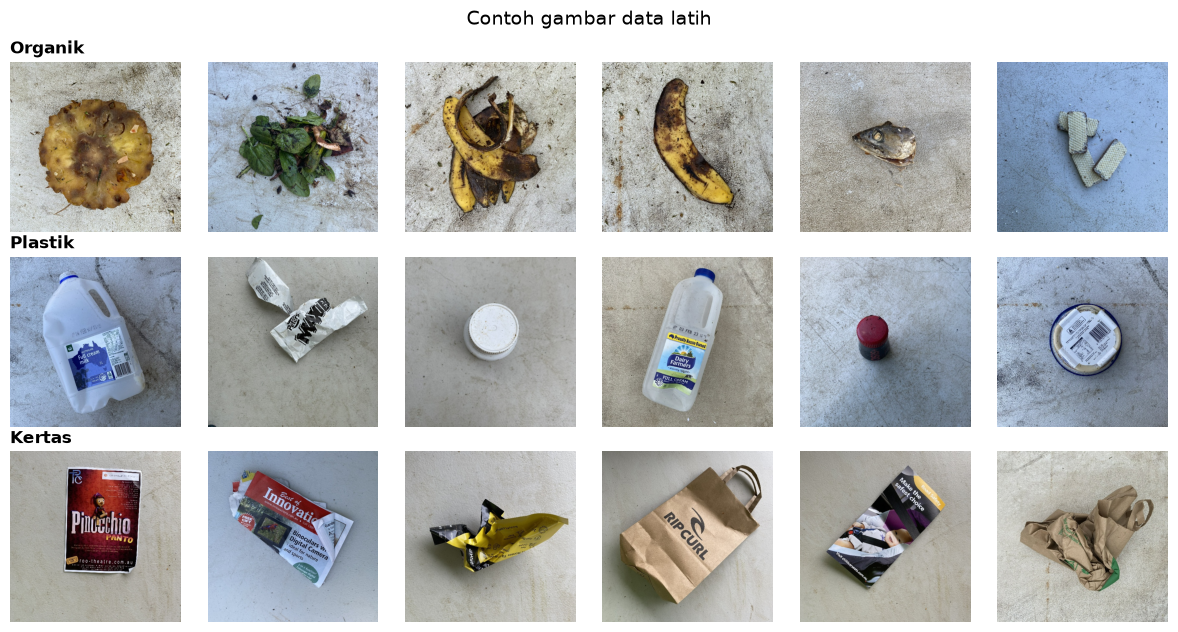

In [3]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for row_axes, category in zip(axes, CLASSES):
    samples = [r for r in rows if r["split"] == "train" and r["category"] == category][:: 47][:6]
    for ax, sample in zip(row_axes, samples):
        ax.imshow(PILImage.open(ML / "data" / sample["path"]))
        ax.set_axis_off()
    row_axes[0].set_title(LABELS[category], loc="left", fontsize=12, fontweight="bold")
fig.suptitle("Contoh gambar data latih", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Pelatihan

- Backbone MobileNetV3-Small pretrained ImageNet: kecil, cepat di CPU, cocok untuk layanan serverless.
- Fase 1: hanya classifier head dilatih 5 epoch. Fase 2: fine-tuning seluruh jaringan hingga 30 epoch
  dengan early stopping (patience 7).
- Augmentasi hanya untuk data latih (random crop, flip, rotasi, color jitter). Loss cross-entropy berbobot kelas.
- Checkpoint dipilih dari **macro F1 data validasi**. Pilihan dikunci ke `selection.json` sebelum data uji dibaca,
  jadi data uji tidak pernah dipakai untuk memilih pengaturan.

Setiap run menulis ke folder baru agar hasil sebelumnya tidak tertimpa.

In [4]:
OUT = f"runs/notebook-{time.strftime('%Y%m%d-%H%M%S')}"
started = time.time()
run("train.py", "--output-dir", OUT)
print(f"\nSelesai dalam {(time.time() - started) / 60:.1f} menit -> ml/{OUT}")

{
  "seed": 42,
  "head_epochs": 5,
  "fine_epochs": 30,
  "patience": 7,
  "batch_size": 32,
  "output_dir": "runs/notebook-20261103-080716",
  "architecture": "mobilenet_v3_small",
  "weights": "IMAGENET1K_V1",
  "classes": [
    "ORGANIC",
    "PLASTIC",
    "PAPER"
  ],
  "classWeights": [
    0.8926363125351321,
    0.820671834625323,
    1.5123809523809524
  ],
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "torch": "2.11.0+cu128",
  "python": "3.12.15",
  "manifestSha256": "deb15a7f6ac0e46299e67e3981329aa627671ab4fb17b256342972abc5a06bcc",
  "selectionCriterion": "maximum validation macro F1; ties use lower validation loss",
  "testPolicy": "test is evaluated only after selection.json is written; no test-driven model changes"
}


{"stage": "head", "epoch": 1, "trainLoss": 0.2803862860581136, "trainAccuracy": 0.8860201511335013, "trainMacroF1": 0.8793203222335775, "validationLoss": 0.14095177086179747, "validationAccuracy": 0.9529411764705882, "validationMacroF1": 0.9498926807737208}


{"stage": "head", "epoch": 2, "trainLoss": 0.11029477000837062, "trainAccuracy": 0.957808564231738, "trainMacroF1": 0.9542399826127715, "validationLoss": 0.16475710913210231, "validationAccuracy": 0.9352941176470588, "validationMacroF1": 0.9332264730721042}


{"stage": "head", "epoch": 3, "trainLoss": 0.06943357760269636, "trainAccuracy": 0.9741813602015114, "trainMacroF1": 0.9717603023437378, "validationLoss": 0.07861010983915014, "validationAccuracy": 0.9705882352941176, "validationMacroF1": 0.9693400281486553}


{"stage": "head", "epoch": 4, "trainLoss": 0.053916448910230355, "trainAccuracy": 0.9842569269521411, "trainMacroF1": 0.982463054815281, "validationLoss": 0.0673809847650666, "validationAccuracy": 0.9794117647058823, "validationMacroF1": 0.9778529520053221}


{"stage": "head", "epoch": 5, "trainLoss": 0.04891537071700661, "trainAccuracy": 0.9829974811083123, "trainMacroF1": 0.9817605753747706, "validationLoss": 0.072829440718188, "validationAccuracy": 0.9705882352941176, "validationMacroF1": 0.9686789889193431}


... (18 outputs left out)

{"stage": "fine", "epoch": 19, "trainLoss": 0.004939153417915584, "trainAccuracy": 0.9974811083123426, "trainMacroF1": 0.9976466392967374, "validationLoss": 0.03913392291904208, "validationAccuracy": 0.9882352941176471, "validationMacroF1": 0.9864400305576776}


D:\PROJECT\Assignment\Test_FullstackDev_Bilcode\ml\scripts\train.py:153: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1, 3, 224, 224), artifact / "model.onnx", input_names=["images"], output_names=["logits"], dynamic_axes={"images": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)


{
  "accuracy": 0.9852941176470589,
  "macroF1": 0.9864939241407362,
  "testCount": 340,
  "classificationReport": {
    "ORGANIC": {
      "precision": 0.9767441860465116,
      "recall": 0.9921259842519685,
      "f1-score": 0.984375,
      "support": 127.0
    },
    "PLASTIC": {
      "precision": 0.9854014598540146,
      "recall": 0.9782608695652174,
      "f1-score": 0.9818181818181818,
      "support": 138.0
    },
    "PAPER": {
      "precision": 1.0,
      "recall": 0.9866666666666667,
      "f1-score": 0.9932885906040269,
      "support": 75.0
    },
    "accuracy": 0.9852941176470589,
    "macro avg": {
      "precision": 0.9873818819668422,
      "recall": 0.9856845068279508,
      "f1-score": 0.9864939241407362,
      "support": 340.0
    },
    "weighted avg": {
      "precision": 0.9853879796698852,
      "recall": 0.9852941176470589,
      "f1-score": 0.9853034658417974,
      "support": 340.0
    }
  },
  "confusionMatrix": [
    [
      126,
      1,
      0
    ],



Selesai dalam 20.7 menit -> ml/runs/notebook-20261103-080716


Jumlah epoch tercatat: 24
Epoch terpilih: {
  "selected": {
    "stage": "fine",
    "epoch": 12,
    "trainLoss": 0.010540901521880294,
    "trainAccuracy": 0.9968513853904282,
    "trainMacroF1": 0.9967183609460761,
    "validationLoss": 0.018966177632040962,
    "validationAccuracy": 0.9911764705882353,
    "validationMacroF1": 0.990643841882232
  },
  "trainingSeconds": 1147.8842732000048,
  "modelPtSha256": "e687d8ab58e693f75485050b2b8b2f785e906e65792cd41ea1ccd16dbfabc065",
  "testPreviouslyInspected": false
}


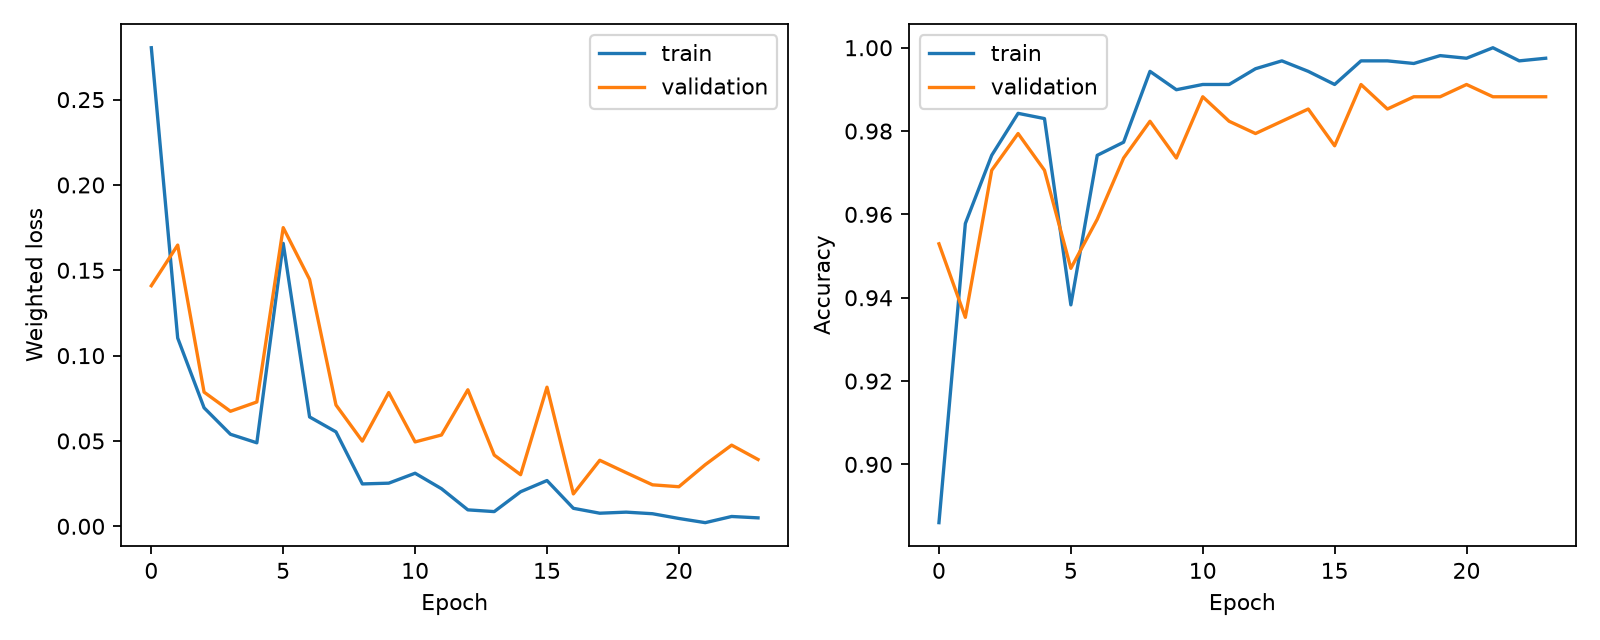

In [5]:
history = json.loads((ML / OUT / "history.json").read_text())
print("Jumlah epoch tercatat:", len(history))
selection = json.loads((ML / OUT / "selection.json").read_text())
print("Epoch terpilih:", json.dumps(selection, indent=2))
display(Image(filename=str(ML / OUT / "evaluation/curves.png"), width=900))

## 3. Evaluasi pada data uji

Data uji (340 gambar) hanya dievaluasi satu kali setelah model dipilih.

In [6]:
metrics = json.loads((ML / OUT / "evaluation/metrics.json").read_text())
report = metrics["classificationReport"]
print(f"Accuracy : {metrics['accuracy']:.4f}  ({round(metrics['accuracy'] * metrics['testCount'])}/{metrics['testCount']})")
print(f"Macro F1 : {metrics['macroF1']:.4f}")
print(f"Target >= 80% tercapai: {metrics['acceptancePassed']}\n")
print("Classification report")
print(f"{'':<14}{'precision':>10}{'recall':>10}{'f1-score':>10}{'support':>10}")
for key in CLASSES + ["macro avg", "weighted avg"]:
    r = report[key]
    name = LABELS.get(key, key)
    print(f"{name:<14}{r['precision']:>10.3f}{r['recall']:>10.3f}{r['f1-score']:>10.3f}{int(r['support']):>10}")
print("\nConfusion matrix (baris = label asli, kolom = prediksi)")
print(f"{'':<10}" + "".join(f"{LABELS[c]:>10}" for c in CLASSES))
for c, row in zip(CLASSES, metrics["confusionMatrix"]):
    print(f"{LABELS[c]:<10}" + "".join(f"{v:>10}" for v in row))

Accuracy : 0.9853  (335/340)
Macro F1 : 0.9865
Target >= 80% tercapai: True

Classification report
               precision    recall  f1-score   support
Organik            0.977     0.992     0.984       127
Plastik            0.985     0.978     0.982       138
Kertas             1.000     0.987     0.993        75
macro avg          0.987     0.986     0.986       340
weighted avg       0.985     0.985     0.985       340

Confusion matrix (baris = label asli, kolom = prediksi)
             Organik   Plastik    Kertas
Organik          126         1         0
Plastik            3       135         0
Kertas             0         1        74


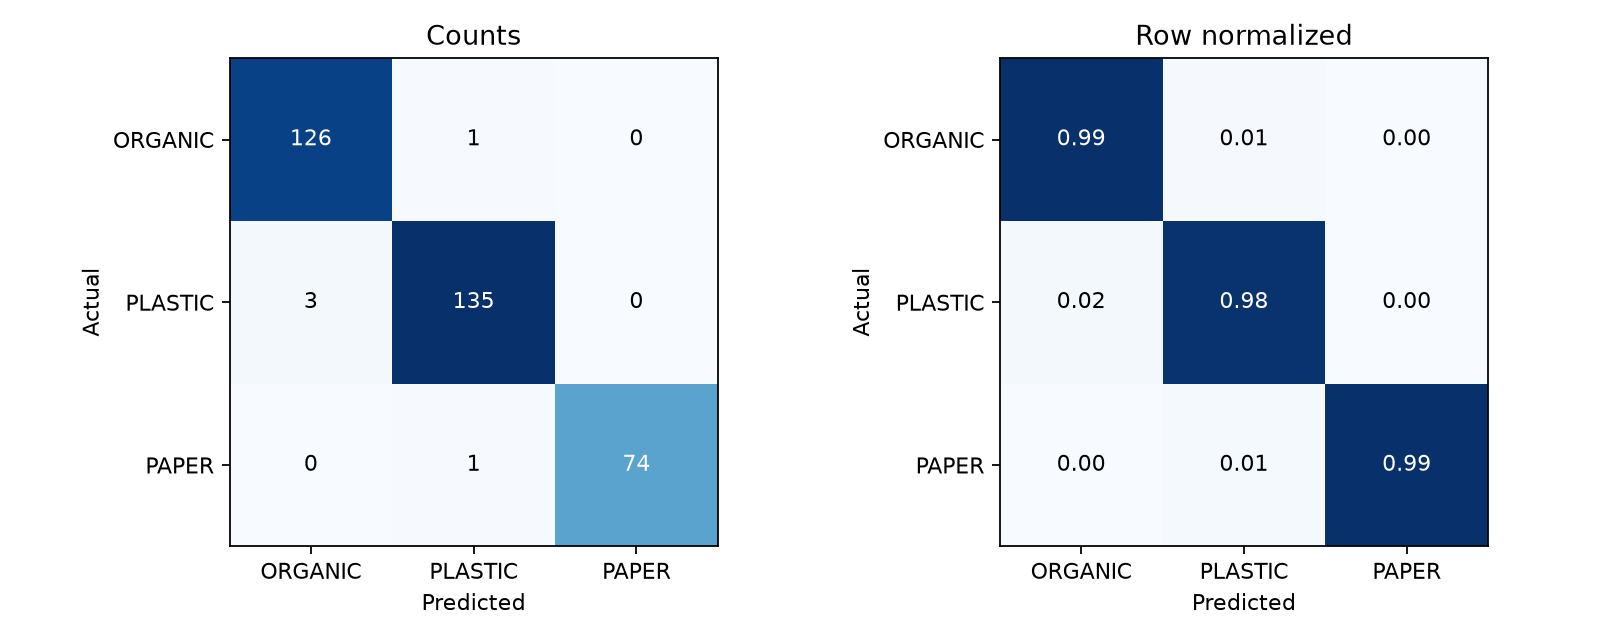

Contoh gambar yang salah diklasifikasi:


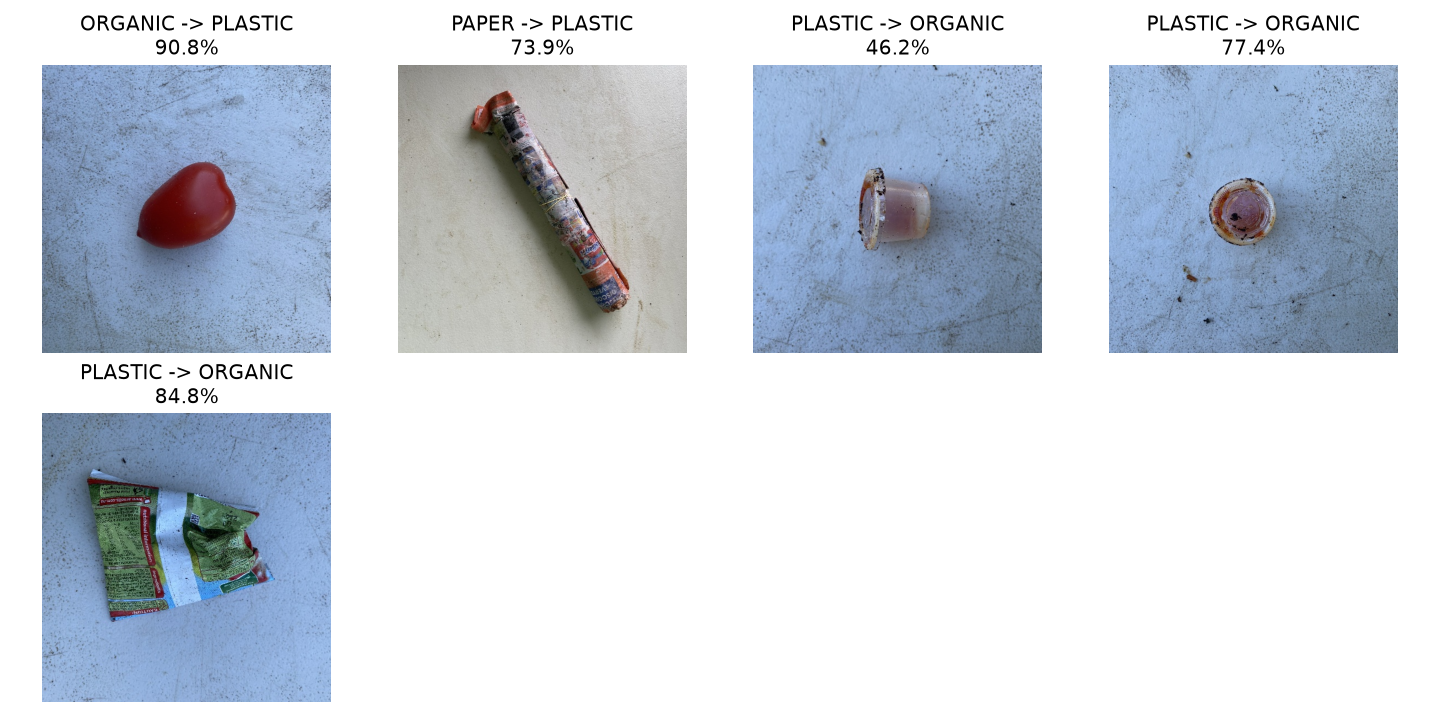

In [7]:
display(Image(filename=str(ML / OUT / "evaluation/confusion-matrix.png"), width=900))
errors = ML / OUT / "evaluation/error-examples.png"
if errors.exists():
    print("Contoh gambar yang salah diklasifikasi:")
    display(Image(filename=str(errors), width=900))

## 4. Perbandingan dengan model yang dideploy

Model di `ml/artifacts/` adalah hasil run resmi yang dipakai API. Run di notebook ini adalah reproduksi
independen; angka bisa sedikit berbeda karena perbedaan perangkat keras dan non-determinisme GPU.

In [8]:
delivered = json.loads((ML / "artifacts/evaluation/metrics.json").read_text())
print(f"{'':<28}{'Notebook':>12}{'Dideploy':>12}")
for key, label in [("accuracy", "Accuracy"), ("macroF1", "Macro F1"),
                   ("onnxTopLabelAgreement", "ONNX = PyTorch (label)"),
                   ("onnxMaxProbabilityError", "Selisih prob. maks ONNX")]:
    print(f"{label:<28}{metrics[key]:>12.6g}{delivered[key]:>12.6g}")
print("\nVersi model dideploy:", delivered["modelVersion"])

                                Notebook    Dideploy
Accuracy                        0.985294    0.985294
Macro F1                        0.986494    0.986494
ONNX = PyTorch (label)                 1           1
Selisih prob. maks ONNX       7.7486e-06  7.7486e-06

Versi model dideploy: realwaste-mobilenetv3-099ff8e5e058


## 5. Inferensi ONNX, persis seperti API

Layanan FastAPI (`ml/inference/app.py`) memakai preprocessing dan model ONNX yang sama.
Sel ini memanggil fungsi yang sama langsung untuk beberapa gambar uji.

Food Organics_102.jpg {'Organik': 1.0, 'Plastik': 0.0, 'Kertas': 0.0}
Plastic_102.jpg {'Organik': 0.0, 'Plastik': 1.0, 'Kertas': 0.0}
Paper_104.jpg {'Organik': 0.0, 'Plastik': 0.0015, 'Kertas': 0.9985}


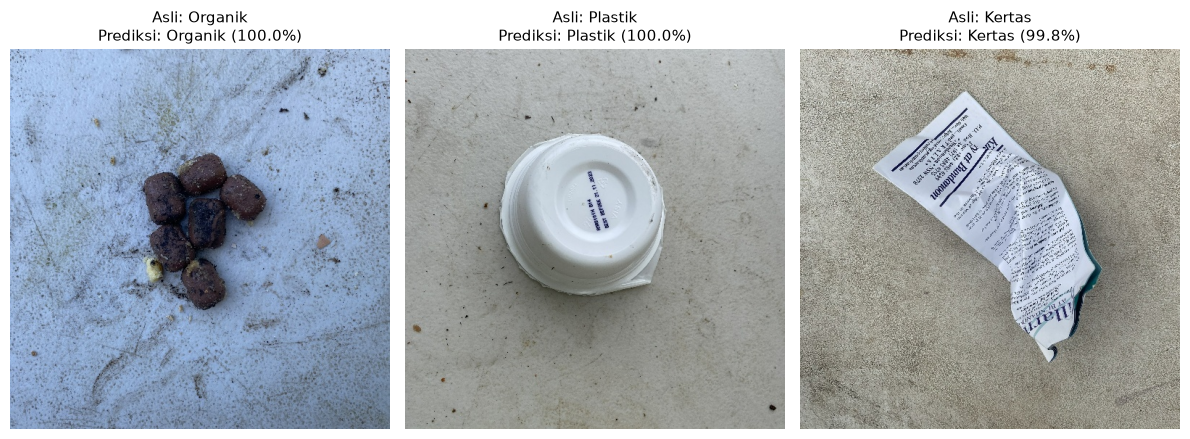

In [9]:
sys.path.insert(0, str(ML / "inference"))
from app import Model, preprocess

model = Model()
model.load()
samples = [next(r for r in rows if r["split"] == "test" and r["category"] == c) for c in CLASSES]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, sample in zip(axes, samples):
    content = (ML / "data" / sample["path"]).read_bytes()
    probabilities = model.predict(preprocess(content))
    top = CLASSES[int(probabilities.argmax())]
    ax.imshow(PILImage.open(ML / "data" / sample["path"]))
    ax.set_axis_off()
    ax.set_title(f"Asli: {LABELS[sample['category']]}\nPrediksi: {LABELS[top]} ({probabilities.max():.1%})", fontsize=11)
    print(sample["path"].split("/")[-1], {LABELS[c]: round(float(p), 4) for c, p in zip(CLASSES, probabilities)})
plt.tight_layout()
plt.show()

## Batasan

- Model mengklasifikasi material dominan pada foto, bukan mendeteksi beberapa objek (tidak ada bounding box).
- Confidence belum dikalibrasi; nilai mendekati 100% bukan jaminan benar. Karena itu aplikasi selalu meminta
  pelapor mengonfirmasi kategori, dan prediksi asli tetap disimpan untuk audit.
- RealWaste difoto dengan latar dan pencahayaan tertentu; foto lapangan di Indonesia bisa berbeda domainnya.